In [1]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor, ExtraTreesRegressor ,AdaBoostRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor
from xgboost import XGBRegressor

In [2]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input,Dense,BatchNormalization,Dropout

c:\Users\Amir sohail\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\export\tf2onnx_lib.py:8: FutureWarning: In the future `np.object` will be defined as the corresponding NumPy scalar.
  if not hasattr(np, "object"):


In [3]:
df = pd.read_csv("synthetic_food_delivery_transactions.csv")
df.head()

,order_id,customer_id,customer_loyalty_tier,customer_acquisition_channel,customer_signup_date,restaurant_id,restaurant_cuisine,restaurant_city,restaurant_rating,restaurant_avg_prep_time,...,total_amount,discount_code,discount_type,discount_value,order_status,weather_temperature,weather_precipitation,is_weekend,is_holiday,event_flag
0,4002,925,Gold,social_media,2024-07-22,124,American,Los Angeles,3.6,23,...,25.42,PROMO-BFUZ,percentage,4.97,completed,2.9,25.6,True,True,NaN
1,4879,3163,Bronze,referral,2023-03-17,43,Chinese,Houston,4.8,32,...,22.70,NaN,NaN,0.00,completed,4.0,0.4,True,True,NaN
2,1124,4154,Bronze,referral,2023-01-14,188,American,San Antonio,3.4,11,...,27.74,NaN,NaN,0.00,completed,4.4,0.0,True,True,NaN
3,6764,4530,Bronze,email,2024-02-26,91,Mediterranean,New York,3.1,17,...,31.85,NaN,NaN,0.00,completed,9.9,0.0,True,True,NaN
4,9073,2570,Bronze,paid_ads,2024-08-25,84,Mediterranean,San Antonio,3.2,28,...,28.46,NaN,NaN,0.00,completed,7.0,16.1,True,True,NaN


In [4]:
df.shape

(10000, 31)

In [5]:
df.columns

Index(['order_id', 'customer_id', 'customer_loyalty_tier',
       'customer_acquisition_channel', 'customer_signup_date', 'restaurant_id',
       'restaurant_cuisine', 'restaurant_city', 'restaurant_rating',
       'restaurant_avg_prep_time', 'menu_item_id', 'menu_item_name',
       'menu_item_category', 'item_price', 'quantity', 'order_timestamp',
       'delivery_timestamp', 'delivery_duration_actual',
       'delivery_duration_estimated', 'delivery_fee', 'tip', 'total_amount',
       'discount_code', 'discount_type', 'discount_value', 'order_status',
       'weather_temperature', 'weather_precipitation', 'is_weekend',
       'is_holiday', 'event_flag'],
      dtype='object')

In [6]:
df["delivery_duration_actual"]

0       59.0
1       57.0
2       41.0
3       50.0
4       69.0
        ... 
9995    42.0
9996     NaN
9997    68.0
9998    68.0
9999    67.0
Name: delivery_duration_actual, Length: 10000, dtype: float64

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 31 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   order_id                      10000 non-null  int64  
 1   customer_id                   10000 non-null  int64  
 2   customer_loyalty_tier         10000 non-null  object 
 3   customer_acquisition_channel  10000 non-null  object 
 4   customer_signup_date          10000 non-null  object 
 5   restaurant_id                 10000 non-null  int64  
 6   restaurant_cuisine            10000 non-null  object 
 7   restaurant_city               10000 non-null  object 
 8   restaurant_rating             10000 non-null  float64
 9   restaurant_avg_prep_time      10000 non-null  int64  
 10  menu_item_id                  10000 non-null  int64  
 11  menu_item_name                10000 non-null  object 
 12  menu_item_category            10000 non-null  object 
 13  it

In [8]:
df.describe()

,order_id,customer_id,restaurant_id,restaurant_rating,restaurant_avg_prep_time,menu_item_id,item_price,quantity,delivery_duration_actual,delivery_duration_estimated,delivery_fee,tip,total_amount,discount_value,weather_temperature,weather_precipitation
count,10000.00000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,9225.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000,10000.000000,10000.000000
mean,6000.50000,5008.065000,101.806200,4.010830,22.278600,548.848900,20.135489,1.380700,48.252033,41.802300,5.019878,3.458260,35.285542,0.96246,14.943640,0.980470
std,2886.89568,2889.998361,57.795156,0.585262,7.093576,319.936271,8.509875,0.743386,11.630734,9.203439,1.732529,3.533187,22.571144,2.33411,7.681618,2.912181
min,1001.00000,1.000000,1.000000,3.000000,10.000000,1.000000,5.030000,1.000000,16.000000,20.000000,1.990000,0.000000,2.480000,0.00000,-5.200000,0.000000
25%,3500.75000,2490.000000,52.000000,3.500000,16.000000,270.000000,12.590000,1.000000,40.000000,35.000000,3.530000,1.127500,20.807500,0.00000,8.400000,0.000000
50%,6000.50000,4982.500000,101.000000,4.100000,22.000000,546.000000,20.460000,1.000000,48.000000,42.000000,5.020000,2.490000,30.525000,0.00000,14.800000,0.000000
75%,8500.25000,7544.250000,152.000000,4.500000,28.000000,824.000000,27.520000,2.000000,56.000000,48.250000,6.540000,4.580000,40.330000,0.00000,21.500000,0.000000
max,11000.00000,9999.000000,200.000000,5.000000,34.000000,1109.000000,34.940000,4.000000,89.000000,63.000000,7.990000,33.220000,176.500000,26.81000,33.800000,36.000000


In [9]:
null = df.isnull().sum()
null[null>0]

delivery_timestamp           775
delivery_duration_actual     775
discount_code               8050
discount_type               8050
event_flag                  9210
dtype: int64

In [10]:
col = ["restaurant_rating", "restaurant_avg_prep_time", "item_price", "quantity", "delivery_duration_estimated", "delivery_fee", "tip", "total_amount", "discount_value", "weather_temperature", "weather_precipitation","delivery_duration_actual","customer_loyalty_tier","customer_acquisition_channel","restaurant_cuisine","order_timestamp","restaurant_city","is_holiday","is_weekend"]

dro_col = df.drop(columns=col,axis=1).columns

df.drop(columns=dro_col,axis=1,inplace=True)

df.head()

,customer_loyalty_tier,customer_acquisition_channel,restaurant_cuisine,restaurant_city,restaurant_rating,restaurant_avg_prep_time,item_price,quantity,order_timestamp,delivery_duration_actual,delivery_duration_estimated,delivery_fee,tip,total_amount,discount_value,weather_temperature,weather_precipitation,is_weekend,is_holiday
0,Gold,social_media,American,Los Angeles,3.6,23,24.86,1,2023-01-01 00:10:17,59.0,48,3.48,2.05,25.42,4.97,2.9,25.6,True,True
1,Bronze,referral,Chinese,Houston,4.8,32,15.25,1,2023-01-01 00:29:15,57.0,54,5.24,2.21,22.70,0.00,4.0,0.4,True,True
2,Bronze,referral,American,San Antonio,3.4,11,18.50,1,2023-01-01 04:06:27,41.0,29,5.95,3.29,27.74,0.00,4.4,0.0,True,True
3,Bronze,email,Mediterranean,New York,3.1,17,24.51,1,2023-01-01 05:05:28,50.0,42,7.27,0.07,31.85,0.00,9.9,0.0,True,True
4,Bronze,paid_ads,Mediterranean,San Antonio,3.2,28,23.50,1,2023-01-01 08:46:51,69.0,52,4.06,0.90,28.46,0.00,7.0,16.1,True,True


In [11]:
df.duplicated().sum()

np.int64(0)

In [12]:
df.dropna(inplace=True)
df.head()

,customer_loyalty_tier,customer_acquisition_channel,restaurant_cuisine,restaurant_city,restaurant_rating,restaurant_avg_prep_time,item_price,quantity,order_timestamp,delivery_duration_actual,delivery_duration_estimated,delivery_fee,tip,total_amount,discount_value,weather_temperature,weather_precipitation,is_weekend,is_holiday
0,Gold,social_media,American,Los Angeles,3.6,23,24.86,1,2023-01-01 00:10:17,59.0,48,3.48,2.05,25.42,4.97,2.9,25.6,True,True
1,Bronze,referral,Chinese,Houston,4.8,32,15.25,1,2023-01-01 00:29:15,57.0,54,5.24,2.21,22.70,0.00,4.0,0.4,True,True
2,Bronze,referral,American,San Antonio,3.4,11,18.50,1,2023-01-01 04:06:27,41.0,29,5.95,3.29,27.74,0.00,4.4,0.0,True,True
3,Bronze,email,Mediterranean,New York,3.1,17,24.51,1,2023-01-01 05:05:28,50.0,42,7.27,0.07,31.85,0.00,9.9,0.0,True,True
4,Bronze,paid_ads,Mediterranean,San Antonio,3.2,28,23.50,1,2023-01-01 08:46:51,69.0,52,4.06,0.90,28.46,0.00,7.0,16.1,True,True


In [13]:
df["order_timestamp"][2]

'2023-01-01 04:06:27'

In [14]:
def hr(date:str):
    return int(date.split(" ")[1].split(":")[0])
def min(date:str):
    return int(date.split(" ")[1].split(":")[1])

df["order_hr"] = df["order_timestamp"].apply(hr)
df["order_min"] = df["order_timestamp"].apply(min)

df.drop("order_timestamp",axis=1,inplace=True)

df.head()

,customer_loyalty_tier,customer_acquisition_channel,restaurant_cuisine,restaurant_city,restaurant_rating,restaurant_avg_prep_time,item_price,quantity,delivery_duration_actual,delivery_duration_estimated,delivery_fee,tip,total_amount,discount_value,weather_temperature,weather_precipitation,is_weekend,is_holiday,order_hr,order_min
0,Gold,social_media,American,Los Angeles,3.6,23,24.86,1,59.0,48,3.48,2.05,25.42,4.97,2.9,25.6,True,True,0,10
1,Bronze,referral,Chinese,Houston,4.8,32,15.25,1,57.0,54,5.24,2.21,22.70,0.00,4.0,0.4,True,True,0,29
2,Bronze,referral,American,San Antonio,3.4,11,18.50,1,41.0,29,5.95,3.29,27.74,0.00,4.4,0.0,True,True,4,6
3,Bronze,email,Mediterranean,New York,3.1,17,24.51,1,50.0,42,7.27,0.07,31.85,0.00,9.9,0.0,True,True,5,5
4,Bronze,paid_ads,Mediterranean,San Antonio,3.2,28,23.50,1,69.0,52,4.06,0.90,28.46,0.00,7.0,16.1,True,True,8,46


In [15]:
bool_col = ["is_weekend","is_holiday"]

df[bool_col] = df[bool_col].astype(int)
df.head()

,customer_loyalty_tier,customer_acquisition_channel,restaurant_cuisine,restaurant_city,restaurant_rating,restaurant_avg_prep_time,item_price,quantity,delivery_duration_actual,delivery_duration_estimated,delivery_fee,tip,total_amount,discount_value,weather_temperature,weather_precipitation,is_weekend,is_holiday,order_hr,order_min
0,Gold,social_media,American,Los Angeles,3.6,23,24.86,1,59.0,48,3.48,2.05,25.42,4.97,2.9,25.6,1,1,0,10
1,Bronze,referral,Chinese,Houston,4.8,32,15.25,1,57.0,54,5.24,2.21,22.70,0.00,4.0,0.4,1,1,0,29
2,Bronze,referral,American,San Antonio,3.4,11,18.50,1,41.0,29,5.95,3.29,27.74,0.00,4.4,0.0,1,1,4,6
3,Bronze,email,Mediterranean,New York,3.1,17,24.51,1,50.0,42,7.27,0.07,31.85,0.00,9.9,0.0,1,1,5,5
4,Bronze,paid_ads,Mediterranean,San Antonio,3.2,28,23.50,1,69.0,52,4.06,0.90,28.46,0.00,7.0,16.1,1,1,8,46


In [16]:
num_cols = df.select_dtypes("number").columns.tolist()
cat_cols = df.select_dtypes("object").columns.tolist()

print(num_cols)
print(cat_cols)

['restaurant_rating', 'restaurant_avg_prep_time', 'item_price', 'quantity', 'delivery_duration_actual', 'delivery_duration_estimated', 'delivery_fee', 'tip', 'total_amount', 'discount_value', 'weather_temperature', 'weather_precipitation', 'is_weekend', 'is_holiday', 'order_hr', 'order_min']
['customer_loyalty_tier', 'customer_acquisition_channel', 'restaurant_cuisine', 'restaurant_city']


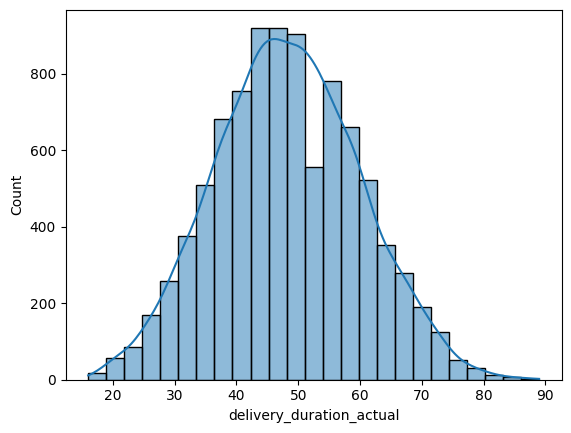

In [17]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.histplot(df,x=num_cols.pop(4),bins=25,kde=True)
plt.show()

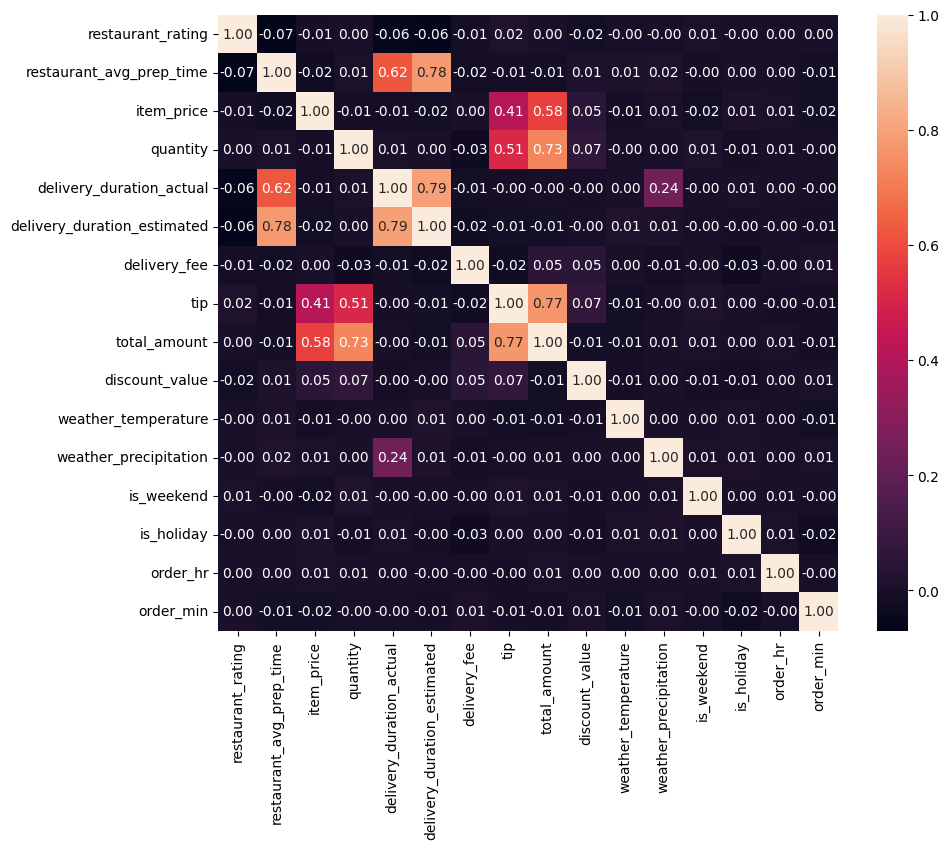

In [18]:
plt.figure(figsize=(10,8))
sns.heatmap(df.corr(numeric_only=True),annot=True,fmt=".2f")
plt.show()

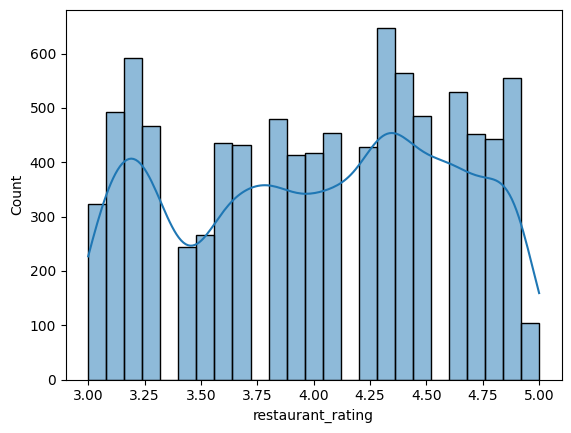

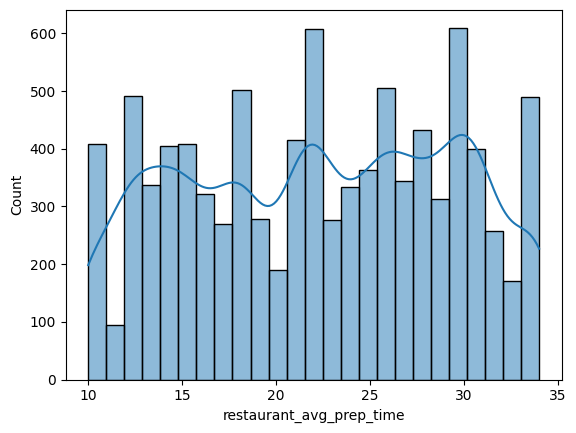

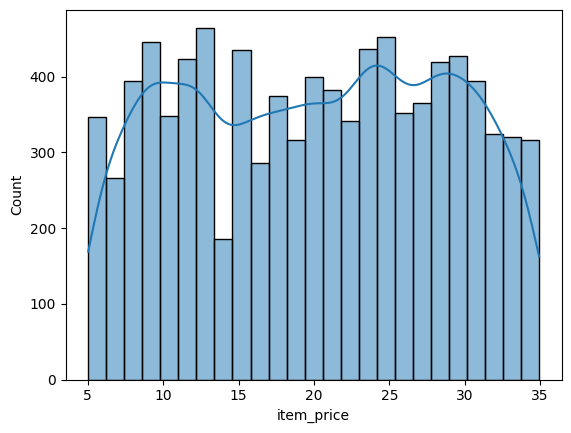

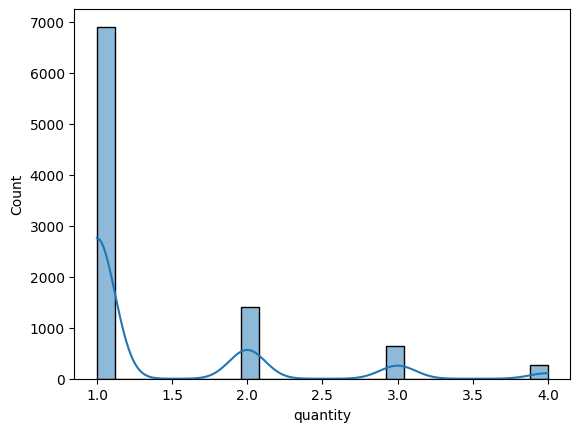

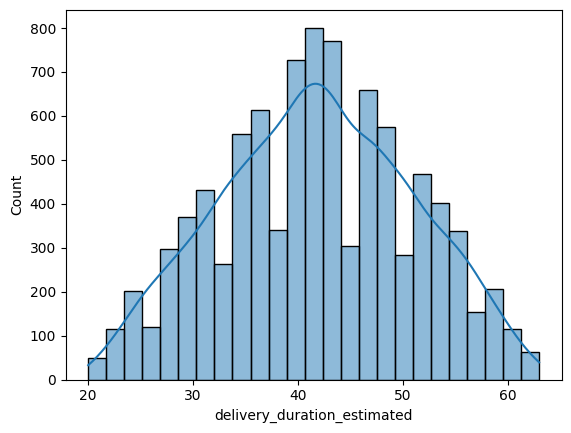

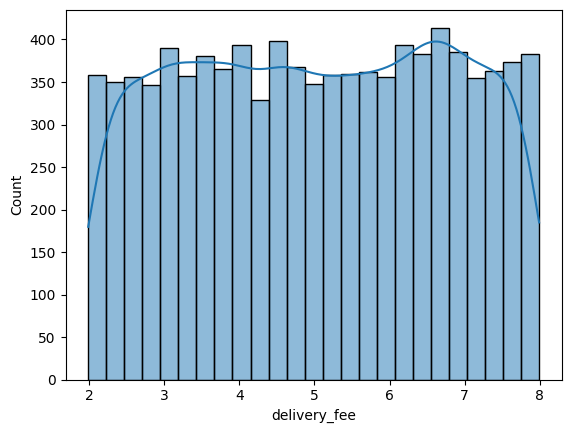

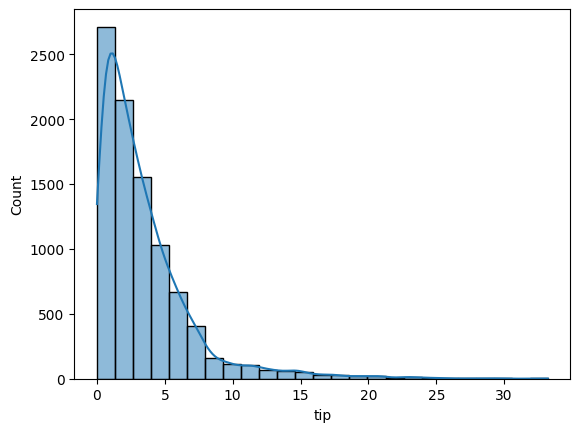

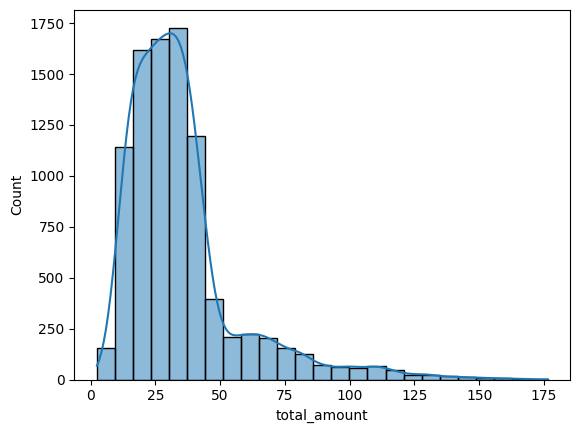

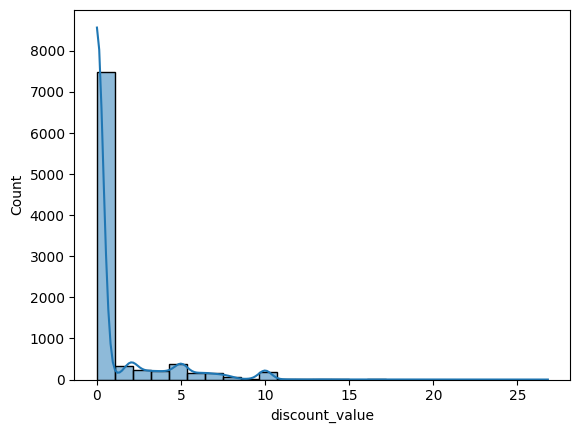

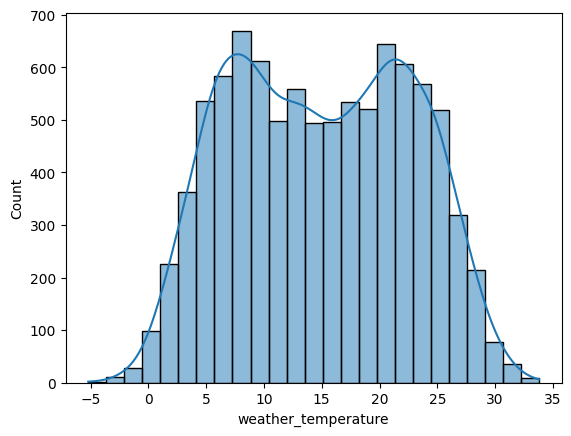

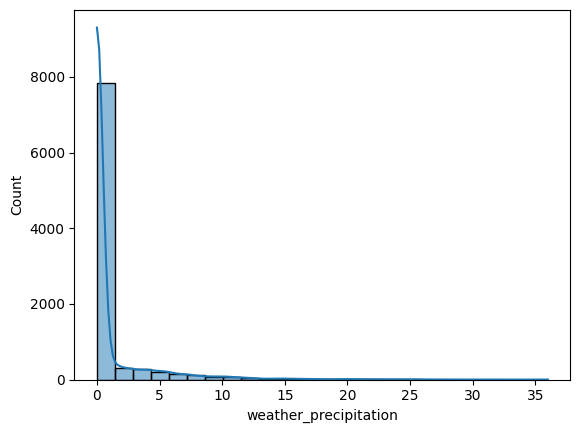

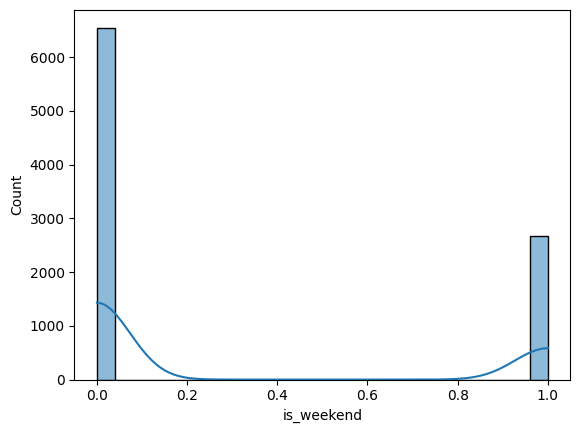

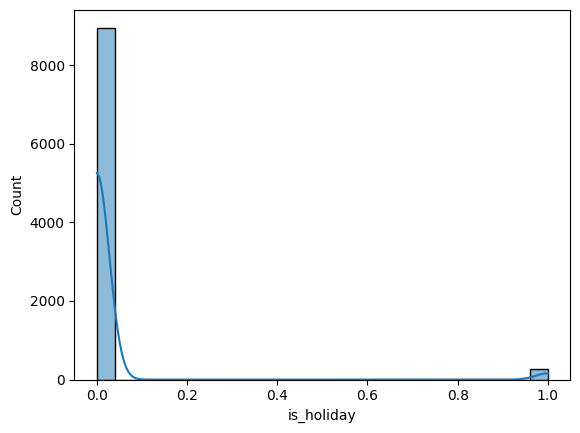

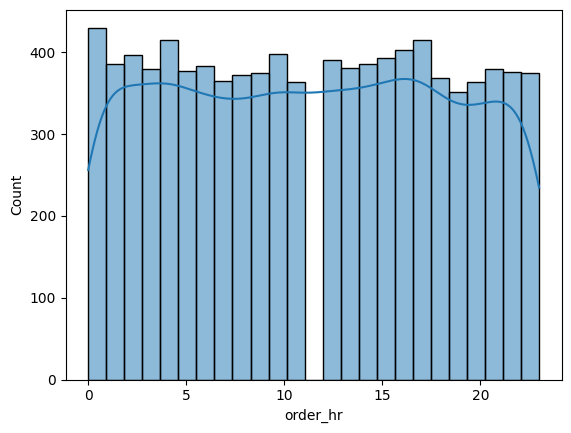

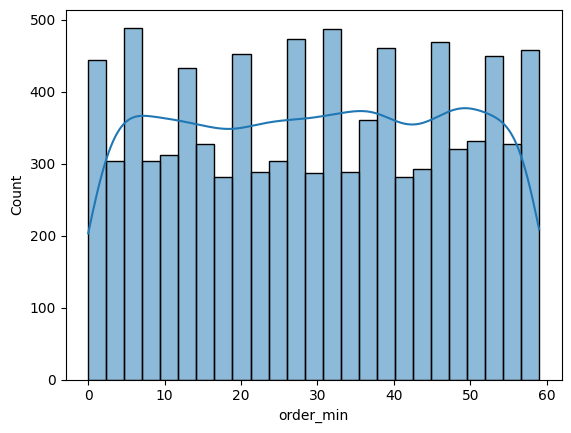

In [19]:
for i in num_cols:
    sns.histplot(df,x=i,bins=25,kde=True)
    plt.show()

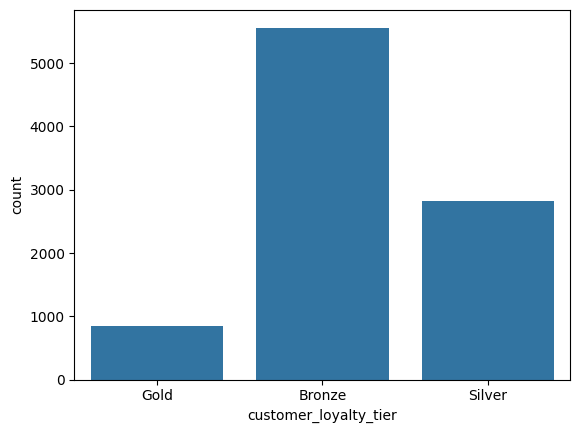

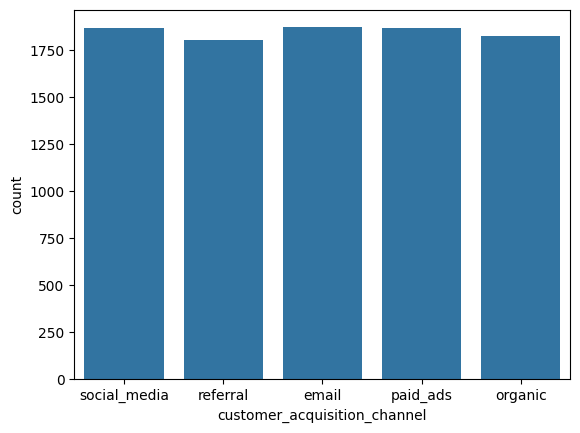

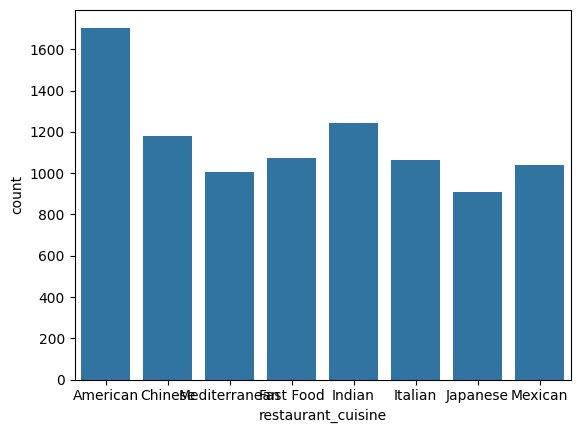

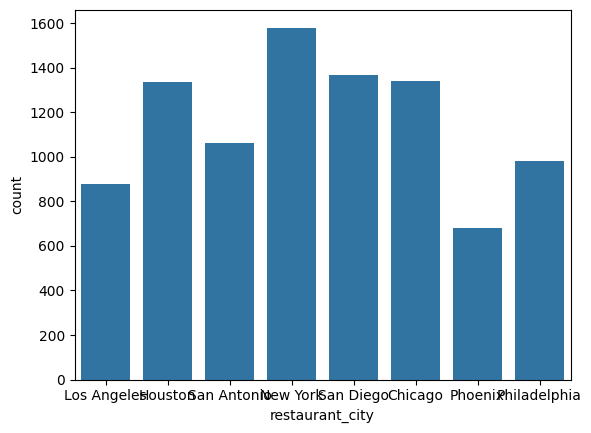

In [20]:
for i in cat_cols:
    sns.countplot(df,x=i)
    plt.show()

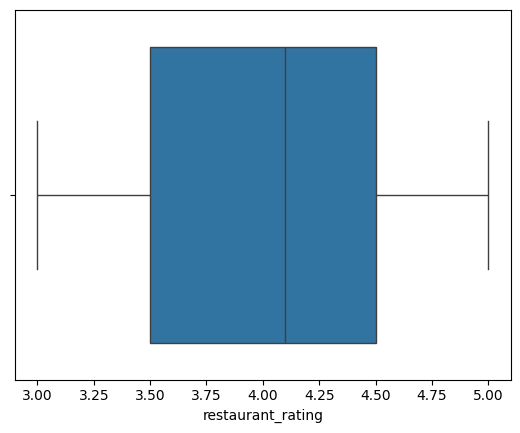

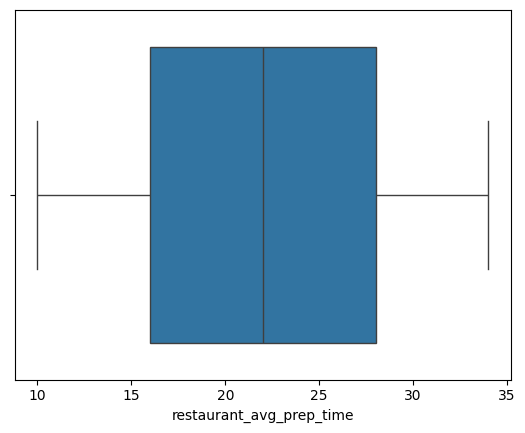

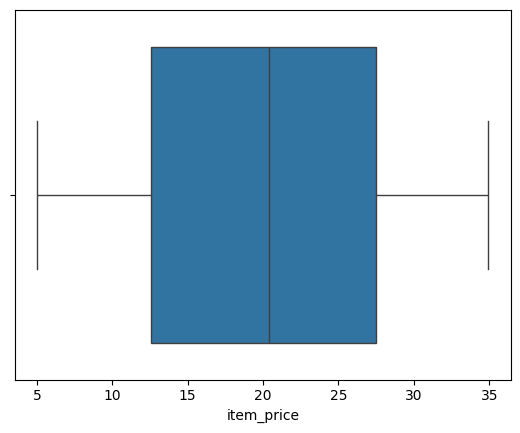

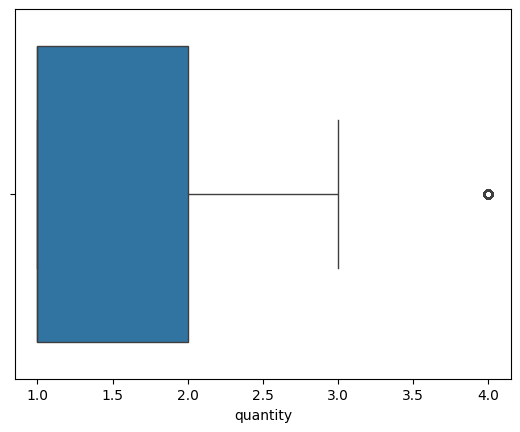

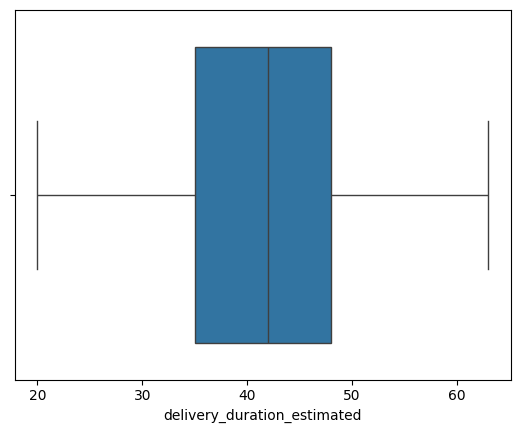

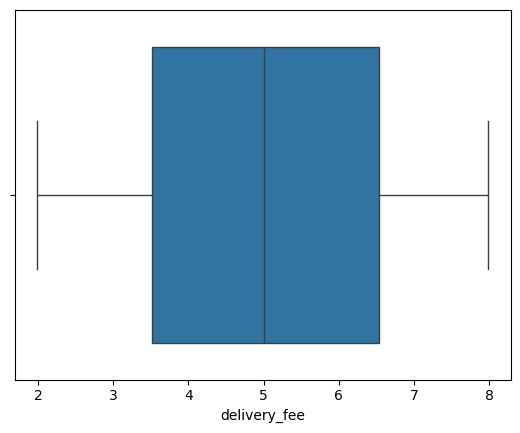

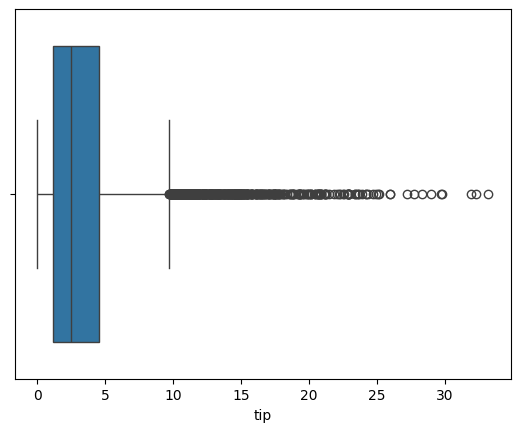

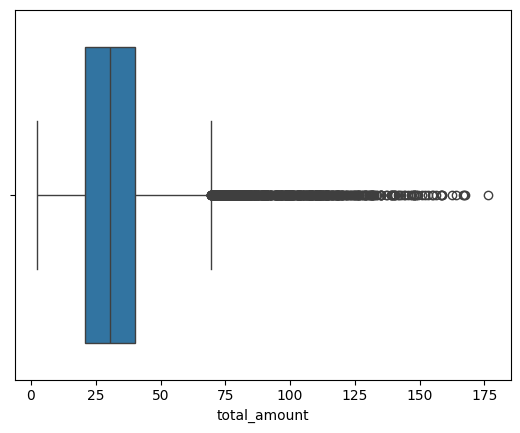

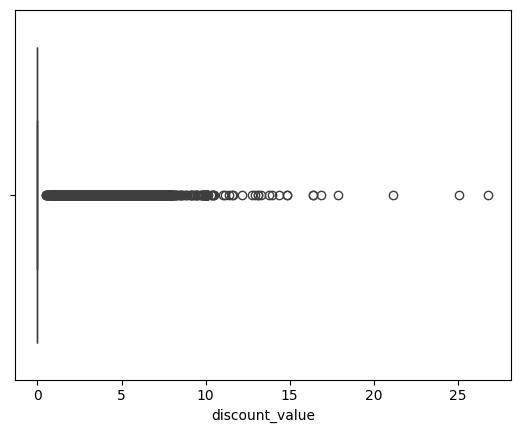

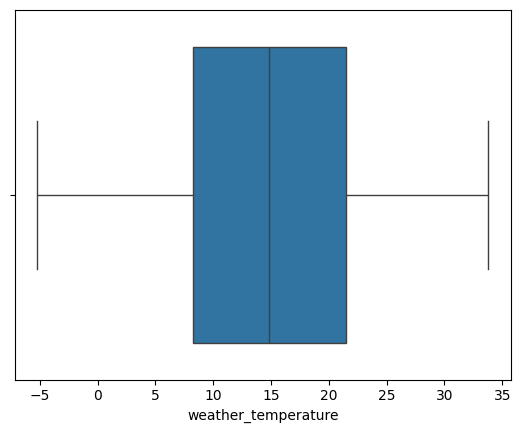

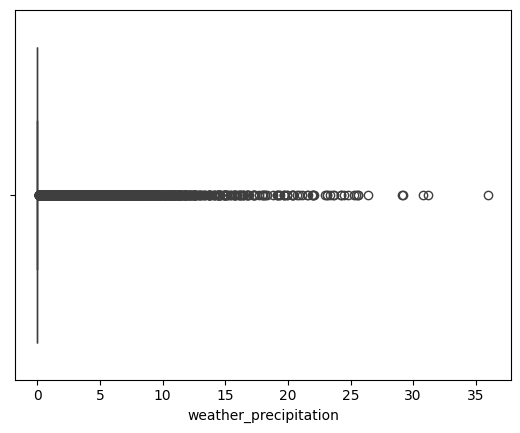

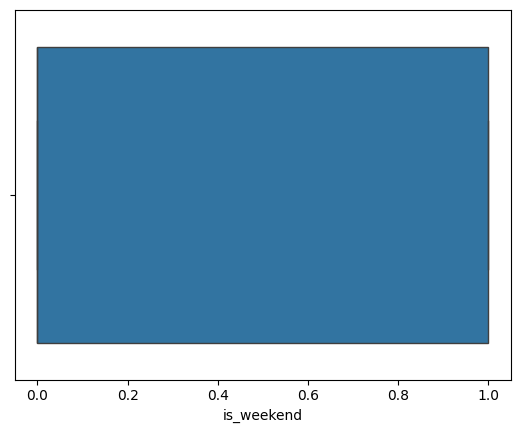

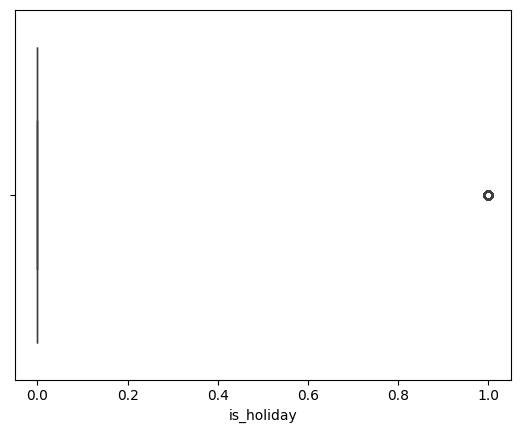

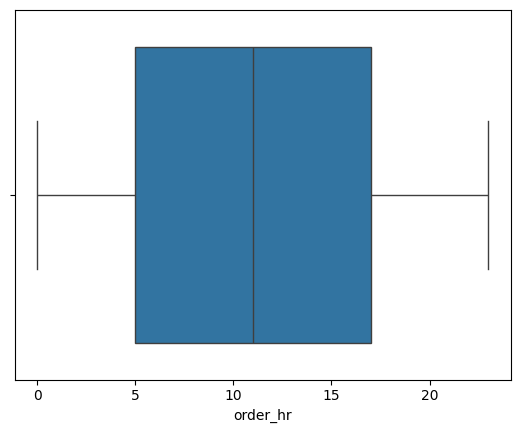

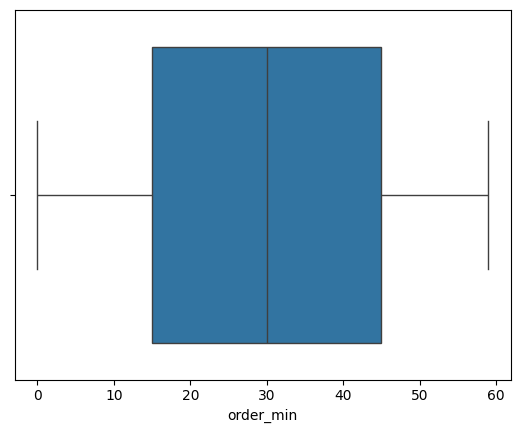

In [21]:
for i in num_cols:
    sns.boxplot(df,x=i)
    plt.show()

In [22]:
from sklearn.preprocessing import StandardScaler,PowerTransformer,OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer

In [23]:
X = df.drop("delivery_duration_actual",axis=1)
y = df["delivery_duration_actual"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)

In [24]:
preporcessor = ColumnTransformer([
    ("num",Pipeline([
        ("impute",SimpleImputer(strategy="median")),
        ("skew",PowerTransformer(method="yeo-johnson")),
        ("scaler",StandardScaler())
    ]),num_cols),
    ("cat",Pipeline([
        ("impute",SimpleImputer(strategy="most_frequent")),
        ("encode",OneHotEncoder(handle_unknown="ignore"))
    ]),cat_cols)

])

preporcessor

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. e.g. `

In [25]:
X_train_pre = preporcessor.fit_transform(X_train)
X_test_pre = preporcessor.transform(X_test)

In [26]:
model_ann = Sequential([
    Input(shape=(X_train_pre.shape[1],)),
    Dense(64,activation="relu"),
    BatchNormalization(),
    Dense(32,activation="relu"),
    BatchNormalization(),
    Dropout(0.2),
    Dense(16,activation="relu"),
    BatchNormalization(),
    Dense(8,activation="relu"),
    Dense(1,activation="linear")
])

In [27]:
model_ann.compile(optimizer="adam",loss="mae",metrics=["r2_score"])

In [28]:
from tensorflow.keras.callbacks import EarlyStopping

his = model_ann.fit(
    X_train_pre,y_train,
    validation_data = (X_test_pre,y_test),
    epochs = 100,batch_size = 64,
    callbacks=[EarlyStopping(
        monitor="val_loss",
        patience=10,
        restore_best_weights=True
    )],
    verbose = 1
)

Epoch 1/100
116/116 ━━━━━━━━━━━━━━━━━━━━ 5s 8ms/step - loss: 46.2069 - r2_score: -15.6528 - val_loss: 43.8976 - val_r2_score: -14.4813
Epoch 2/100
116/116 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 38.9779 - r2_score: -11.3399 - val_loss: 27.6999 - val_r2_score: -6.5624
Epoch 3/100
116/116 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 24.4129 - r2_score: -5.0896 - val_loss: 17.4288 - val_r2_score: -2.2000
Epoch 4/100
116/116 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 13.8357 - r2_score: -1.2953 - val_loss: 13.0271 - val_r2_score: -0.7477
Epoch 5/100
116/116 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 10.2320 - r2_score: -0.2743 - val_loss: 7.4066 - val_r2_score: 0.2452
Epoch 6/100
116/116 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 8.9140 - r2_score: 0.0389 - val_loss: 7.7964 - val_r2_score: 0.2363
Epoch 7/100
116/116 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 7.8364 - r2_score: 0.2719 - val_loss: 8.5096 - val_r2_score: 0.1675
Epoch 8/100
116/116 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 6.9362 - r2_sco

In [29]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor, ExtraTreesRegressor ,AdaBoostRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor
from xgboost import XGBRegressor

In [30]:
results = []
models = {
    'Linear Regression': LinearRegression(),
    'Ridge Regression': Ridge(alpha=1.0),
    'Lasso Regression': Lasso(alpha=0.1, max_iter=10000),
    'ElasticNet': ElasticNet(alpha=0.1, l1_ratio=0.5),
    'Decision Tree': DecisionTreeRegressor(random_state=42),
    'Random Forest': RandomForestRegressor(random_state=42, n_jobs=-1),
    'Extra Trees': ExtraTreesRegressor(random_state=42, n_jobs=-1),
    'Gradient Boosting': GradientBoostingRegressor(random_state=42),
    'K-Neighbors': KNeighborsRegressor(),
    'Support Vector Regressor': SVR(kernel='rbf'),
    "XGBoost": XGBRegressor(random_state=42),
    "AdaBoost": AdaBoostRegressor(random_state=42),
}

In [31]:
for name,model in models.items():
    model.fit(X_train_pre,y_train)
    y_pred = model.predict(X_test_pre)
    R2_score = r2_score(y_test,y_pred)
    MSE = mean_squared_error(y_test, y_pred)
    MAE = mean_absolute_error(y_test, y_pred)
    RMSE = np.sqrt(MSE)
    results.append({
        "Name":name,
        "R2_score":R2_score,
        "MSE":MSE,
        "MAE":MAE,
        "RMSE":RMSE
    })

results_df = pd.DataFrame(results)
results_df

,Name,R2_score,MSE,MAE,RMSE
0,Linear Regression,0.728372,35.929965,5.127943,5.994161
1,Ridge Regression,0.728372,35.929940,5.127958,5.994159
2,Lasso Regression,0.729987,35.716284,5.115626,5.976310
3,ElasticNet,0.726205,36.216570,5.139803,6.018020
4,Decision Tree,0.447309,73.107859,6.969106,8.550313
5,Random Forest,0.717247,37.401515,5.175816,6.115678
6,Extra Trees,0.696719,40.116801,5.322260,6.333783
7,Gradient Boosting,0.730021,35.711853,5.102045,5.975940
8,K-Neighbors,0.550934,59.400759,6.264715,7.707189
9,Support Vector Regressor,0.691270,40.837569,5.374675,6.390428


In [32]:
model_pipeline = Pipeline([
    ("preporcessor",preporcessor),
    ("model",AdaBoostRegressor(random_state=42))
])
model_pipeline.fit(X_train,y_train)
y_pred = model_pipeline.predict(X_test)
R2_score = r2_score(y_test,y_pred)
MSE = mean_squared_error(y_test, y_pred)
MAE = mean_absolute_error(y_test, y_pred)
RMSE = np.sqrt(MSE)

print(R2_score)
print(MSE)
print(MAE)
print(RMSE)

0.7278968737842153
35.992762611511914
5.126494006777315
5.999396853977232


In [33]:
from joblib import dump

dump(model_pipeline,"model_pipeline.pkl")
dump(preporcessor,"preporcessor.pkl")

['preporcessor.pkl']